First five rows of dataset:
   Age  AnnualIncome
0   20         20000
1   22         22000
2   25         25000
3   28         28000
4   35         50000

Clustered dataset:
   Age  AnnualIncome  Cluster
0   20         20000        2
1   22         22000        2
2   25         25000        2
3   28         28000        2
4   35         50000        0
5   38         55000        0
6   40         60000        0
7   45         65000        0
8   50         90000        1
9   55         95000        1

Cluster counts:
Cluster
0    4
1    4
2    4
Name: count, dtype: int64


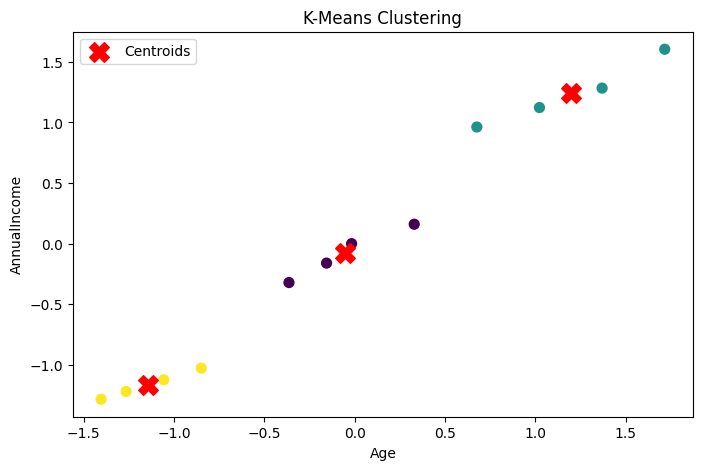


Clustered data saved to clustered_data.csv


In [1]:

# K-Means Clustering using a CSV file

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 1: Load the CSV dataset
df = pd.read_csv("data.csv")

print("First five rows of dataset:")
print(df.head())

# Step 2: Select numerical columns
X = df.select_dtypes(include="number")

if X.shape[1] < 2:
    raise ValueError("The CSV must contain at least two numeric columns.")

# Step 3: Handle missing values
X = X.fillna(X.median())

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Apply K-Means clustering
k = 3
model = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = model.fit_predict(X_scaled)

# Step 6: Add cluster labels to the dataset
df["Cluster"] = clusters

print("\nClustered dataset:")
print(df.head(10))

print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

# Step 7: Visualize clusters using the first two numeric features
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=clusters, cmap="viridis", s=50
)

centers = model.cluster_centers_
plt.scatter(
    centers[:, 0], centers[:, 1],
    c="red", marker="X", s=200, label="Centroids"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Step 8: Save the clustered dataset
df.to_csv("clustered_data.csv", index=False)
print("\nClustered data saved to clustered_data.csv")
